###<font color='red'>Made by Anton Rudchenko for ParKinSim (Parallel Kinematic Simulation) project.</font>

#<font color='orange'>This is an overview of different machine learning models' performance for solving inverse kinematic problem of Metrom (Pentapod) machine.

In [ ]:
#@title <font color='yellow'>Imports

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

##<font color='yellow'>Importing and preprocessing data collected from solving direct kinematics in simulation.

In [ ]:
data = pd.read_csv('DKd.csv')

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY  \
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039   
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043   
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047   
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054   
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042   
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...   
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400   
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390   
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381   
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372   
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363   

          RZ  
0      0.045  
1      0.048  
2     

There are some dublicate data entries from direct kinematics, it is a good practice to get rid of those.

In [ ]:
data = data.drop_duplicates()

print(data)

         L1    L2    L3    L4    L5        X       Y        Z     RX     RY  \
0      14.0  16.0  15.0  15.0  15.0    6.225 -36.857  -29.095  0.255  0.039   
1      13.0  16.0  15.0  15.0  15.0    6.911 -39.529  -26.396  0.274  0.043   
2      12.0  16.0  15.0  15.0  15.0    7.764 -43.206  -23.034  0.301  0.047   
3      11.0  16.0  15.0  15.0  15.0    8.963 -48.874  -18.280  0.342  0.054   
4      11.0  15.0  15.0  15.0  15.0    7.614 -56.939  -13.149  0.400  0.042   
...     ...   ...   ...   ...   ...      ...     ...      ...    ...    ...   
10187  87.0  64.0  19.0   8.0  89.0 -104.324  24.796 -110.492 -0.203 -0.400   
10188  87.0  64.0  19.0   7.0  89.0 -103.399  24.096 -111.093 -0.193 -0.390   
10189  87.0  64.0  19.0   6.0  89.0 -102.454  23.377 -111.680 -0.184 -0.381   
10190  87.0  64.0  19.0   5.0  89.0 -101.491  22.639 -112.253 -0.174 -0.372   
10191  87.0  64.0  19.0   4.0  89.0 -100.508  21.881 -112.813 -0.164 -0.363   

          RZ  
0      0.045  
1      0.048  
2     

In [ ]:
# This data was generated using ChatGPT and it is based on the simulation dataset
# This is needed for testing the performance of the models based on uknown data

gen_data = pd.read_csv('generated_dataset.csv')

print(gen_data)

    L1  L2  L3  L4  L5       X        Y       Z     RX     RY     RZ
0  NaN NaN NaN NaN NaN  13.012  -30.120 -27.456  0.220  0.075  0.059
1  NaN NaN NaN NaN NaN  15.201  -25.032 -29.784  0.190  0.085  0.061
2  NaN NaN NaN NaN NaN  17.425  -20.841 -31.952  0.162  0.096  0.065
3  NaN NaN NaN NaN NaN  19.673  -16.974 -33.772  0.136  0.107  0.068
4  NaN NaN NaN NaN NaN  21.933  -13.423 -35.343  0.112  0.118  0.072
5  NaN NaN NaN NaN NaN -67.450  102.784 -28.135 -1.048 -0.130  0.286
6  NaN NaN NaN NaN NaN -68.350  100.183 -30.562 -1.031 -0.132  0.282
7  NaN NaN NaN NaN NaN -68.725   98.472 -33.028 -1.014 -0.134  0.278
8  NaN NaN NaN NaN NaN -69.124   96.738 -35.442 -0.997 -0.136  0.274
9  NaN NaN NaN NaN NaN -69.529   94.982 -37.805 -0.980 -0.138  0.270
10 NaN NaN NaN NaN NaN -65.375  118.102 -14.008 -0.818 -0.378  0.067
11 NaN NaN NaN NaN NaN -67.475  116.287 -14.112 -0.806 -0.390  0.066
12 NaN NaN NaN NaN NaN -69.581  114.441 -14.180 -0.794 -0.403  0.065
13 NaN NaN NaN NaN NaN -71.703  11

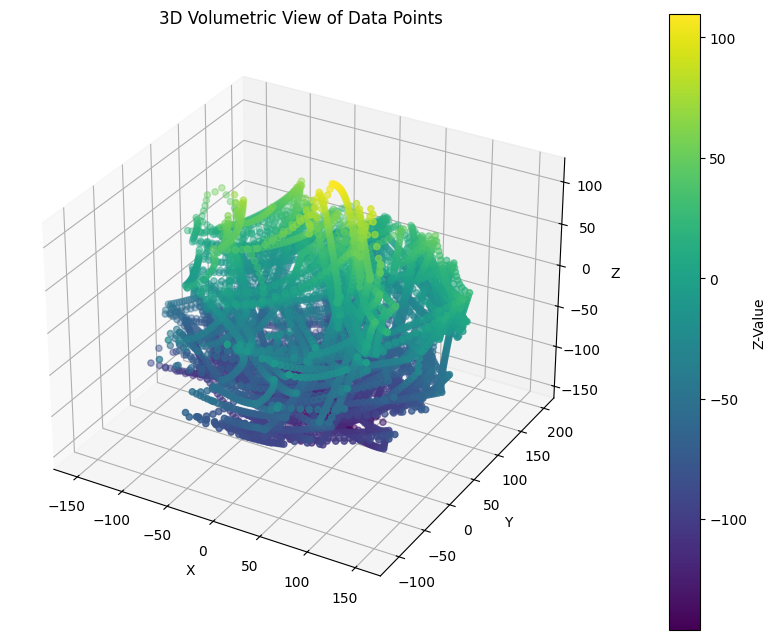

In [ ]:
#@title Plotting XYZ on volumetric plot
x = data['X']
y = data['Y']
z = data['Z']

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(x, y, z, c=z, cmap='viridis', marker='o')

ax.set_title('3D Volumetric View of Data Points')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

color_bar = fig.colorbar(scatter, ax=ax, pad=0.1)
color_bar.set_label('Z-Value')

plt.show()

<font color='red'>REMARK:</font> The dataset was collected again, after some changes were made to the mechanical design of the pentapod.

Further a reverse kinematics problem is going to be solved via ML - Trying to predict LAs based on coords.

##<font color='orange'>Linear Regression model evaluation - <font color='red'>failed</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 52.6285
  R2 Score: 0.9541
Target L2:
  Mean Squared Error: 37.6156
  R2 Score: 0.9556
Target L3:
  Mean Squared Error: 69.8143
  R2 Score: 0.9387
Target L4:
  Mean Squared Error: 41.6137
  R2 Score: 0.9553
Target L5:
  Mean Squared Error: 72.2716
  R2 Score: 0.9329

Model Coefficients:
           X         Y         Z          RX          RY        RZ
L1 -0.020252 -0.520535 -0.737279  -84.395916    2.141053  1.892564
L2 -0.756099 -0.640928 -0.212786 -104.350913  127.436770 -5.821451
L3  0.653014  0.560211 -0.285186   32.962238  -73.463817 -2.738496
L4  0.633032 -0.654398 -0.196647 -108.278567 -109.785898 -2.615585
L5 -0.609037  0.521298 -0.260836   32.373342   62.516081  9.192129

Model Intercepts:
L1    -4.124193
L2     9.484967
L3    13.553870
L4     9.619234
L5    13.644042
dtype: float64


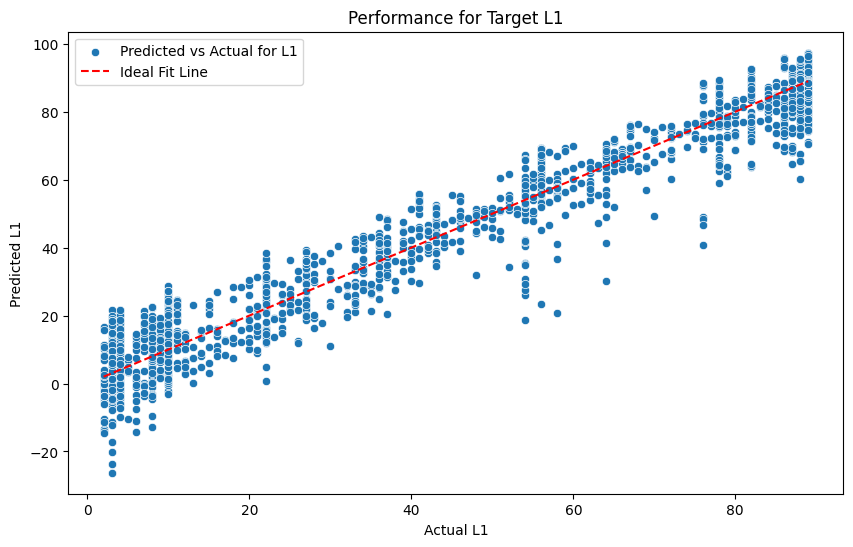

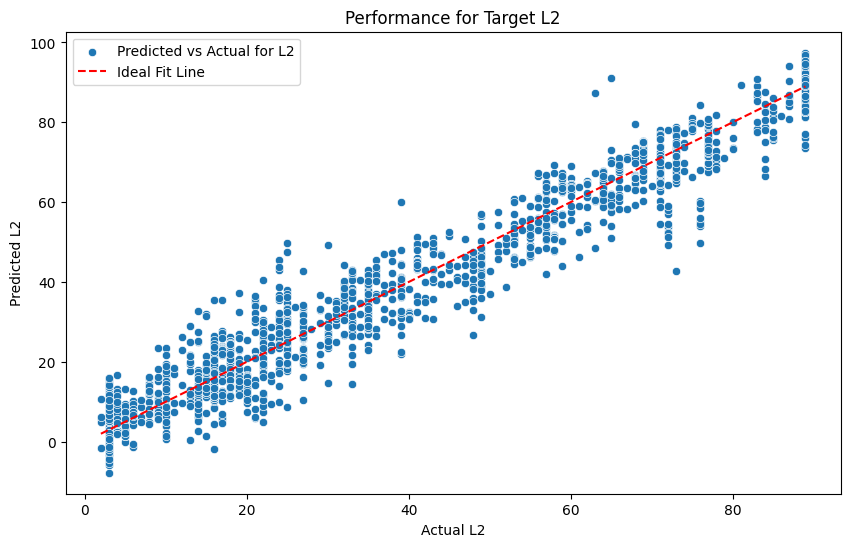

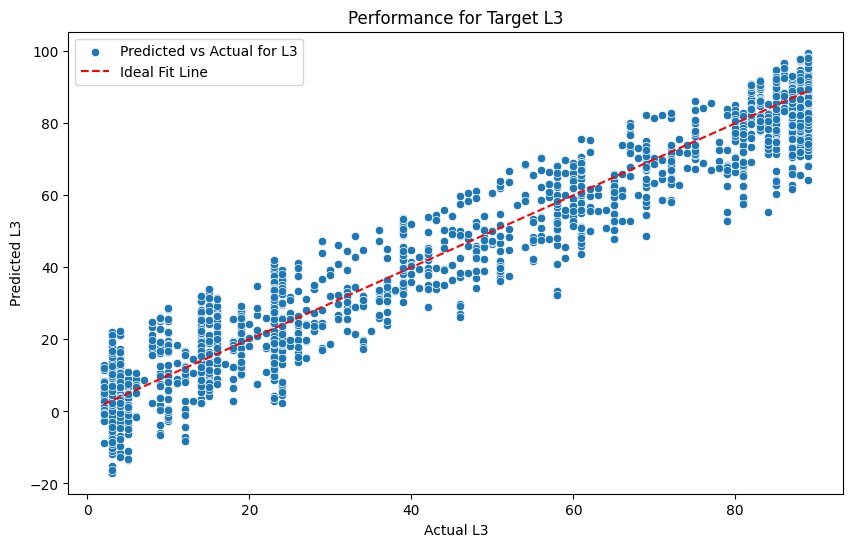

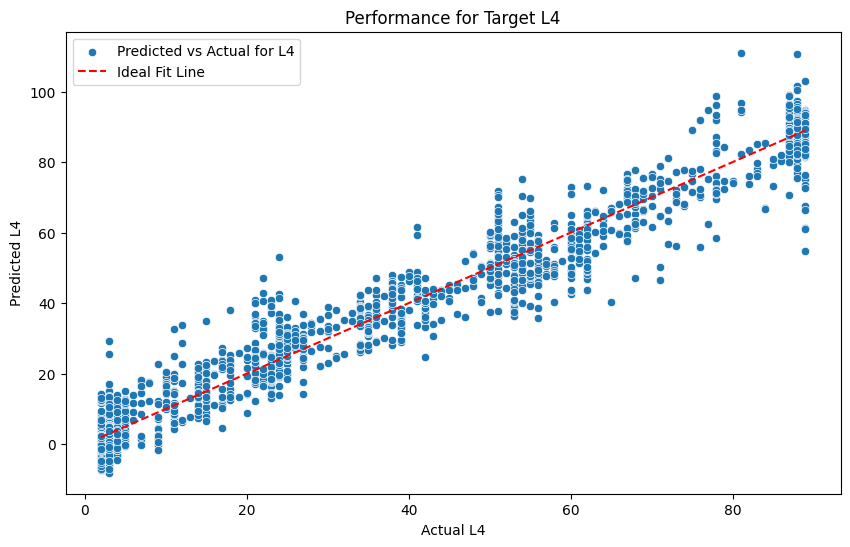

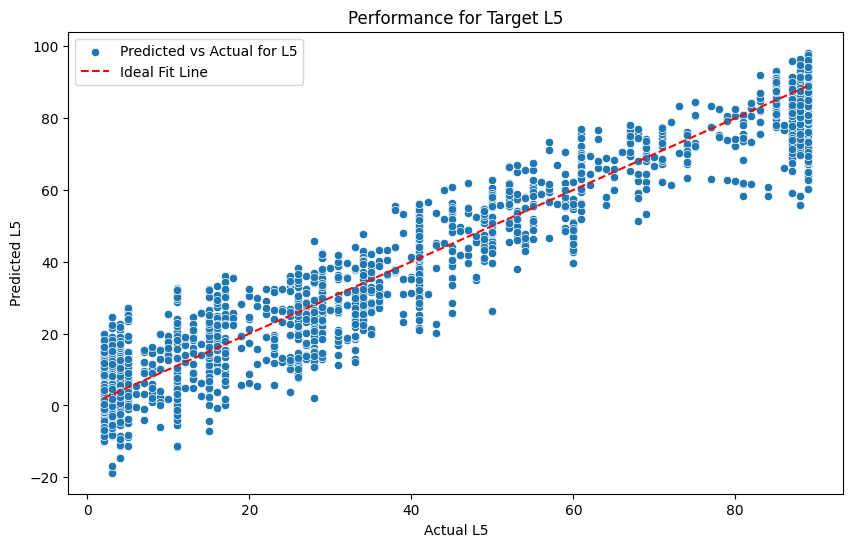

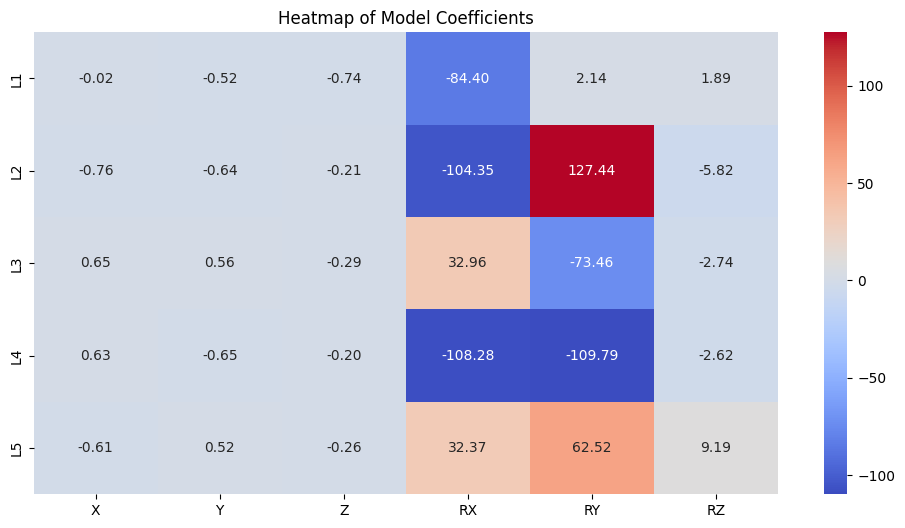

In [ ]:
from sklearn.linear_model import LinearRegression



labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

coefficients = pd.DataFrame(model.coef_, columns=features.columns, index=labels.columns)
intercepts = pd.Series(model.intercept_, index=labels.columns)

print("\nModel Coefficients:")
print(coefficients)
print("\nModel Intercepts:")
print(intercepts)

# Visualization
for i, target in enumerate(labels):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Model Coefficients")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target]).tolist()
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-1.483, 2.608, -44.25, -0.028, 0.047, 0.111]) # The simulation check for these values

[[15.988173852807233, 27.680832904499805, 10.758540623241041, 12.558469321686921, 22.866236785979297]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-1.483, 2.608, -44.25, -0.028, 0.047, 0.111]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

### Testings with generated data

In [ ]:
tests = gen_data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]
tests = tests.values.tolist()

for i in tests[:3]:
  print(i)

[13.012, -30.12, -27.456, 0.22, 0.075, 0.059]
[15.201, -25.032, -29.784, 0.19, 0.085, 0.061]
[17.425, -20.841, -31.952, 0.162, 0.096, 0.065]


In [ ]:
# Predicting Ls based on generated data
with open('la_predictions.txt', 'w') as writefile:
    for i in tests:
        y_pred = model.predict([i]).tolist()
        writefile.write(f'{y_pred[0][0]}, {y_pred[0][1]}, {y_pred[0][2]}, {y_pred[0][3]}, {y_pred[0][4]}\n')

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/

In [ ]:
# Importing results check in simulation
with open("lr_tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

print(res)

[[999.0, 999.0, 999.0, 999.0, 999.0, 999.0], [999.0, 999.0, 999.0, 999.0, 999.0, 999.0], [26.58, -45.709, -27.919, 0.338, 0.143, 0.132], [24.654, -24.969, -40.744, 0.197, 0.132, 0.097], [24.719, -12.082, -47.446, 0.111, 0.131, 0.083], [-58.961, 114.897, -18.089, -1.136, -0.044, 0.296], [-59.583, 112.179, -22.236, -1.109, -0.044, 0.295], [-60.377, 110.488, -25.999, -1.087, -0.049, 0.292], [-61.155, 108.718, -29.641, -1.064, -0.053, 0.29], [-61.906, 106.922, -33.141, -1.043, -0.057, 0.288], [-60.07, 134.916, -16.544, -0.964, -0.323, 0.097], [-62.006, 133.151, -17.103, -0.951, -0.334, 0.097], [-63.93, 131.336, -17.581, -0.939, -0.346, 0.096], [-65.871, 129.434, -18.028, -0.926, -0.358, 0.095], [-67.855, 127.522, -18.385, -0.914, -0.369, 0.095], [-69.841, 125.542, -18.657, -0.901, -0.381, 0.094], [-71.872, 123.455, -18.946, -0.887, -0.393, 0.092], [2.63, 132.996, -75.263, -1.036, 0.078, 0.046], [4.911, 133.117, -71.847, -1.061, 0.101, 0.049], [7.391, 132.942, -68.118, -1.087, 0.127, 0.049]

In [ ]:
#@title plotting function
# ChatGPT made it for me ;3

def plot_comparison(actual, predicted):
    # Check if the lists have the same length
    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lists must have the same length")

    # Extract individual parameters (X, Y, Z, Rx, Ry, Rz)
    actual = list(zip(*actual))  # Transpose to separate parameters
    predicted = list(zip(*predicted))

    # Define parameter labels
    labels = ['X', 'Y', 'Z', 'Rx', 'Ry', 'Rz']

    # Create subplots
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()

    for i, ax in enumerate(axes):
        # Prepare data for plotting
        actual_filtered = [a if a != 999.0 else None for a in actual[i]]
        predicted_filtered = [a if a != 999.0 else None for a in predicted[i]]

        # Plot actual and predicted for the i-th parameter
        ax.plot(range(len(actual_filtered)), actual_filtered, label='Actual', marker='o', linestyle='-', alpha=0.7)
        ax.plot(range(len(predicted_filtered)), predicted_filtered, label='Predicted', marker='x', linestyle='--', alpha=0.7)

        # Add labels, title, and legend
        ax.set_title(f'Comparison for {labels[i]}')
        ax.set_xlabel('Index')
        ax.set_ylabel(labels[i])
        ax.legend()
        ax.grid(True)

    # Adjust layout
    plt.tight_layout()
    plt.show()

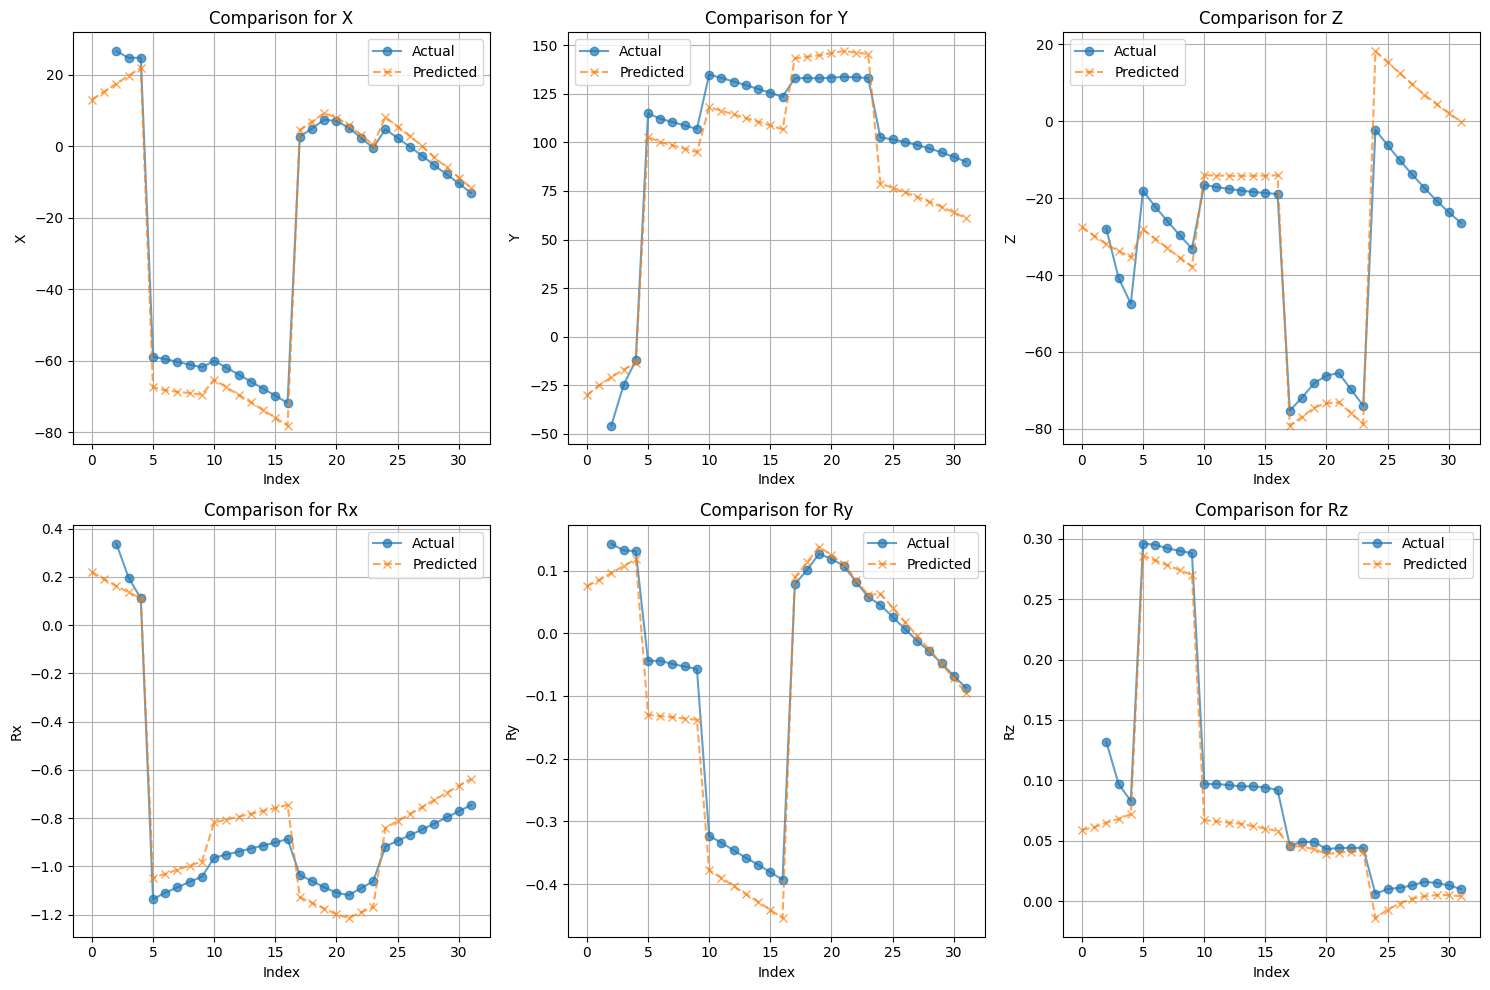

In [ ]:
plot_comparison(res, tests)

In [ ]:
for i in range(0, len(res)):
  print(res[i], tests[i])

[999.0, 999.0, 999.0, 999.0, 999.0, 999.0] [13.012, -30.12, -27.456, 0.22, 0.075, 0.059]
[999.0, 999.0, 999.0, 999.0, 999.0, 999.0] [15.201, -25.032, -29.784, 0.19, 0.085, 0.061]
[26.58, -45.709, -27.919, 0.338, 0.143, 0.132] [17.425, -20.841, -31.952, 0.162, 0.096, 0.065]
[24.654, -24.969, -40.744, 0.197, 0.132, 0.097] [19.673, -16.974, -33.772, 0.136, 0.107, 0.068]
[24.719, -12.082, -47.446, 0.111, 0.131, 0.083] [21.933, -13.423, -35.343, 0.112, 0.118, 0.072]
[-58.961, 114.897, -18.089, -1.136, -0.044, 0.296] [-67.45, 102.784, -28.135, -1.048, -0.13, 0.286]
[-59.583, 112.179, -22.236, -1.109, -0.044, 0.295] [-68.35, 100.183, -30.562, -1.031, -0.132, 0.282]
[-60.377, 110.488, -25.999, -1.087, -0.049, 0.292] [-68.725, 98.472, -33.028, -1.014, -0.134, 0.278]
[-61.155, 108.718, -29.641, -1.064, -0.053, 0.29] [-69.124, 96.738, -35.442, -0.997, -0.136, 0.274]
[-61.906, 106.922, -33.141, -1.043, -0.057, 0.288] [-69.529, 94.982, -37.805, -0.98, -0.138, 0.27]
[-60.07, 134.916, -16.544, -0.964

##<font color='orange'>ElasticNet Model Evaluation - <font color='red'>failed</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 52.6071
  R2 Score: 0.9541
Target L2:
  Mean Squared Error: 37.5629
  R2 Score: 0.9556
Target L3:
  Mean Squared Error: 69.8464
  R2 Score: 0.9387
Target L4:
  Mean Squared Error: 41.6323
  R2 Score: 0.9552
Target L5:
  Mean Squared Error: 72.2868
  R2 Score: 0.9329

Model Coefficients:
           X         Y         Z          RX          RY        RZ
L1 -0.018425 -0.518796 -0.736542  -84.083588    1.773553  1.883763
L2 -0.750108 -0.639277 -0.212199 -104.066610  126.305528 -5.072738
L3  0.651187  0.558475 -0.285911   32.651032  -73.096531 -2.729830
L4  0.631095 -0.652877 -0.196246 -107.995569 -109.420222 -2.634999
L5 -0.607098  0.519780 -0.261224   32.091466   62.150168  9.211421

Model Intercepts:
L1    -4.022556
L2     9.559692
L3    13.453253
L4     9.697831
L5    13.566465
dtype: float64


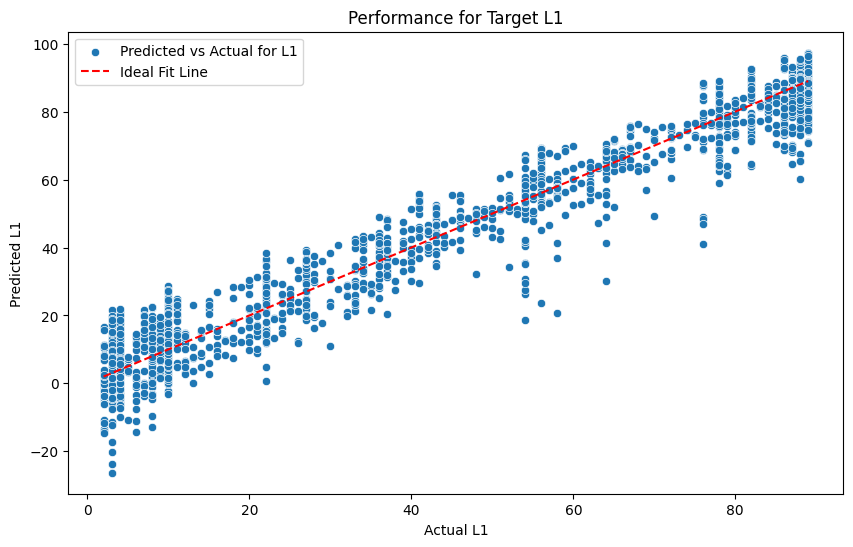

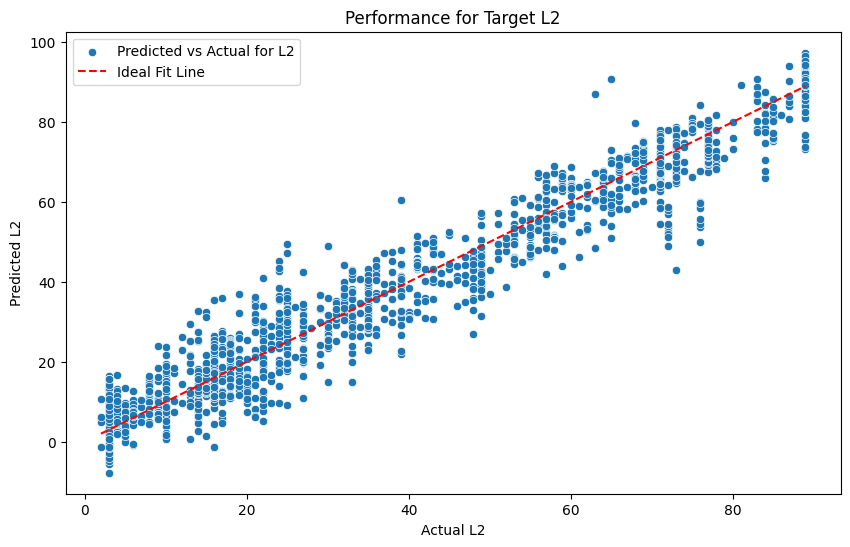

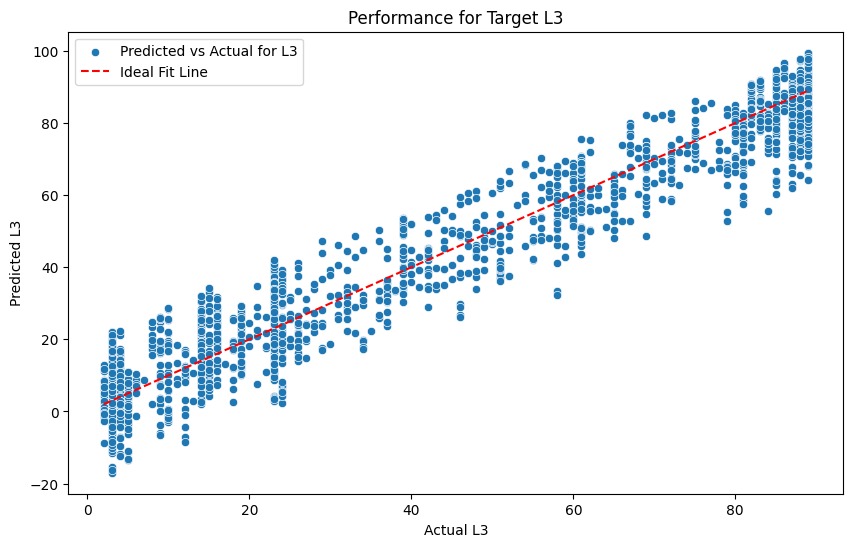

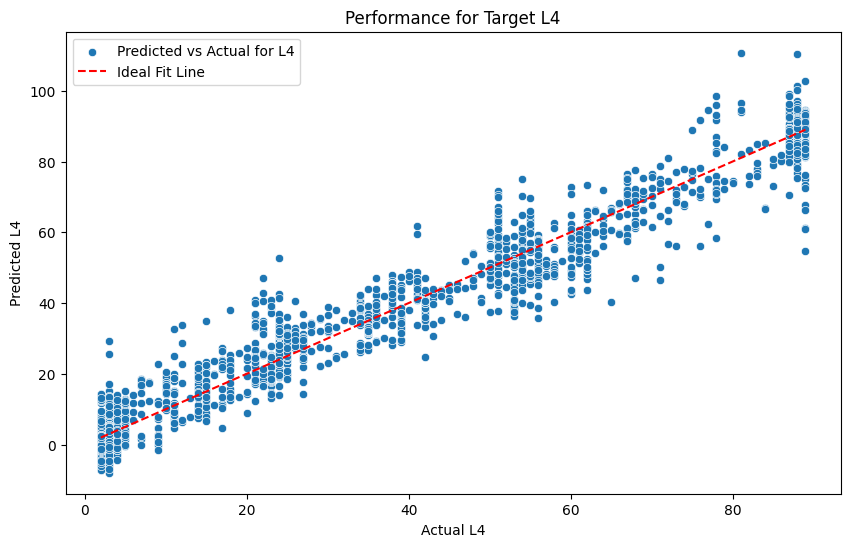

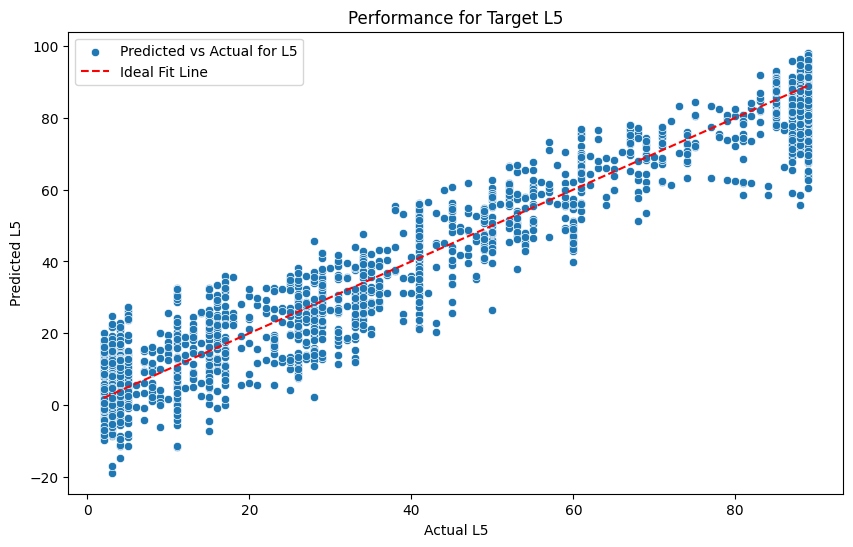

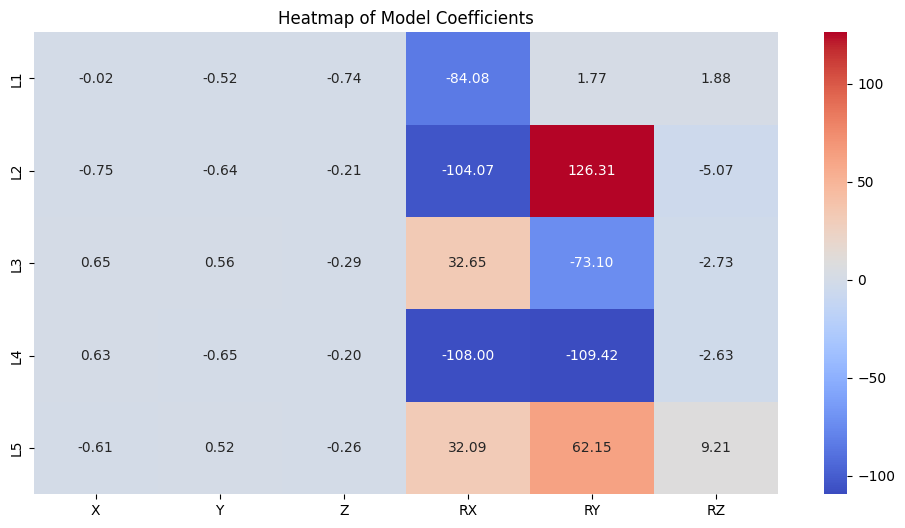

In [ ]:
from sklearn.linear_model import ElasticNet


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)


# Found via Grid Search
alpha = 0.01  # Regularization strength
l1_ratio = 1.0  # Balance between L1 and L2 regularization

model = ElasticNet(alpha=alpha, l1_ratio=l1_ratio, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

coefficients = pd.DataFrame(model.coef_, columns=features.columns, index=labels.columns)
intercepts = pd.Series(model.intercept_, index=labels.columns)

print("\nModel Coefficients:")
print(coefficients)
print("\nModel Intercepts:")
print(intercepts)

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Model Coefficients")
plt.show()

In [ ]:
# Grid Search

from sklearn.model_selection import GridSearchCV

param_grid = {
    'alpha': [0.001, 0.01, 0.1, 1, 10],
    'l1_ratio': [0.1, 0.5, 0.7, 0.9, 1.0]
}
grid_search = GridSearchCV(ElasticNet(), param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Best Alpha:", grid_search.best_params_['alpha'])
print("Best L1 Ratio:", grid_search.best_params_['l1_ratio'])

Best Alpha: 0.001
Best L1 Ratio: 1.0


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-1.43, 2.523, -44.231, -0.028, 0.047, 0.111]) # The simulation check for these values

[[16.0335 27.7335 10.7139 12.6334 22.792 ]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-1.43, 2.523, -44.231, -0.028, 0.047, 0.111]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

In [ ]:
#@title testing on generated data

# Predicting Ls based on generated data
with open('en_predictions.txt', 'w') as writefile:
    for i in tests:
        y_pred = model.predict([i]).tolist()
        writefile.write(f'{y_pred[0][0]}, {y_pred[0][1]}, {y_pred[0][2]}, {y_pred[0][3]}, {y_pred[0][4]}\n')

# Importing results check in simulation
with open("en_tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

print(res)


[[999.0, 999.0, 999.0, 999.0, 999.0, 999.0], [999.0, 999.0, 999.0, 999.0, 999.0, 999.0], [27.423, -49.47, -25.21, 0.363, 0.148, 0.14], [24.962, -26.874, -39.575, 0.208, 0.133, 0.1], [24.889, -13.451, -46.671, 0.119, 0.132, 0.084], [-58.98, 115.243, -17.744, -1.139, -0.045, 0.296], [-59.618, 112.567, -21.834, -1.112, -0.045, 0.295], [-60.371, 110.854, -25.624, -1.09, -0.049, 0.292], [-61.154, 109.113, -29.232, -1.068, -0.054, 0.29], [-61.907, 107.31, -32.74, -1.046, -0.058, 0.288], [-60.081, 134.615, -16.753, -0.961, -0.323, 0.097], [-62.023, 132.832, -17.304, -0.948, -0.334, 0.097], [-63.938, 131.005, -17.779, -0.936, -0.346, 0.096], [-65.9, 129.084, -18.223, -0.923, -0.358, 0.094], [-67.889, 127.164, -18.552, -0.91, -0.369, 0.094], [-69.862, 125.184, -18.802, -0.898, -0.381, 0.093], [-71.895, 123.07, -19.097, -0.883, -0.393, 0.091], [2.751, 133.303, -75.402, -1.036, 0.078, 0.046], [5.022, 133.442, -71.998, -1.061, 0.101, 0.048], [7.469, 133.316, -68.251, -1.088, 0.126, 0.049], [7.056,

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but ElasticNet was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:27

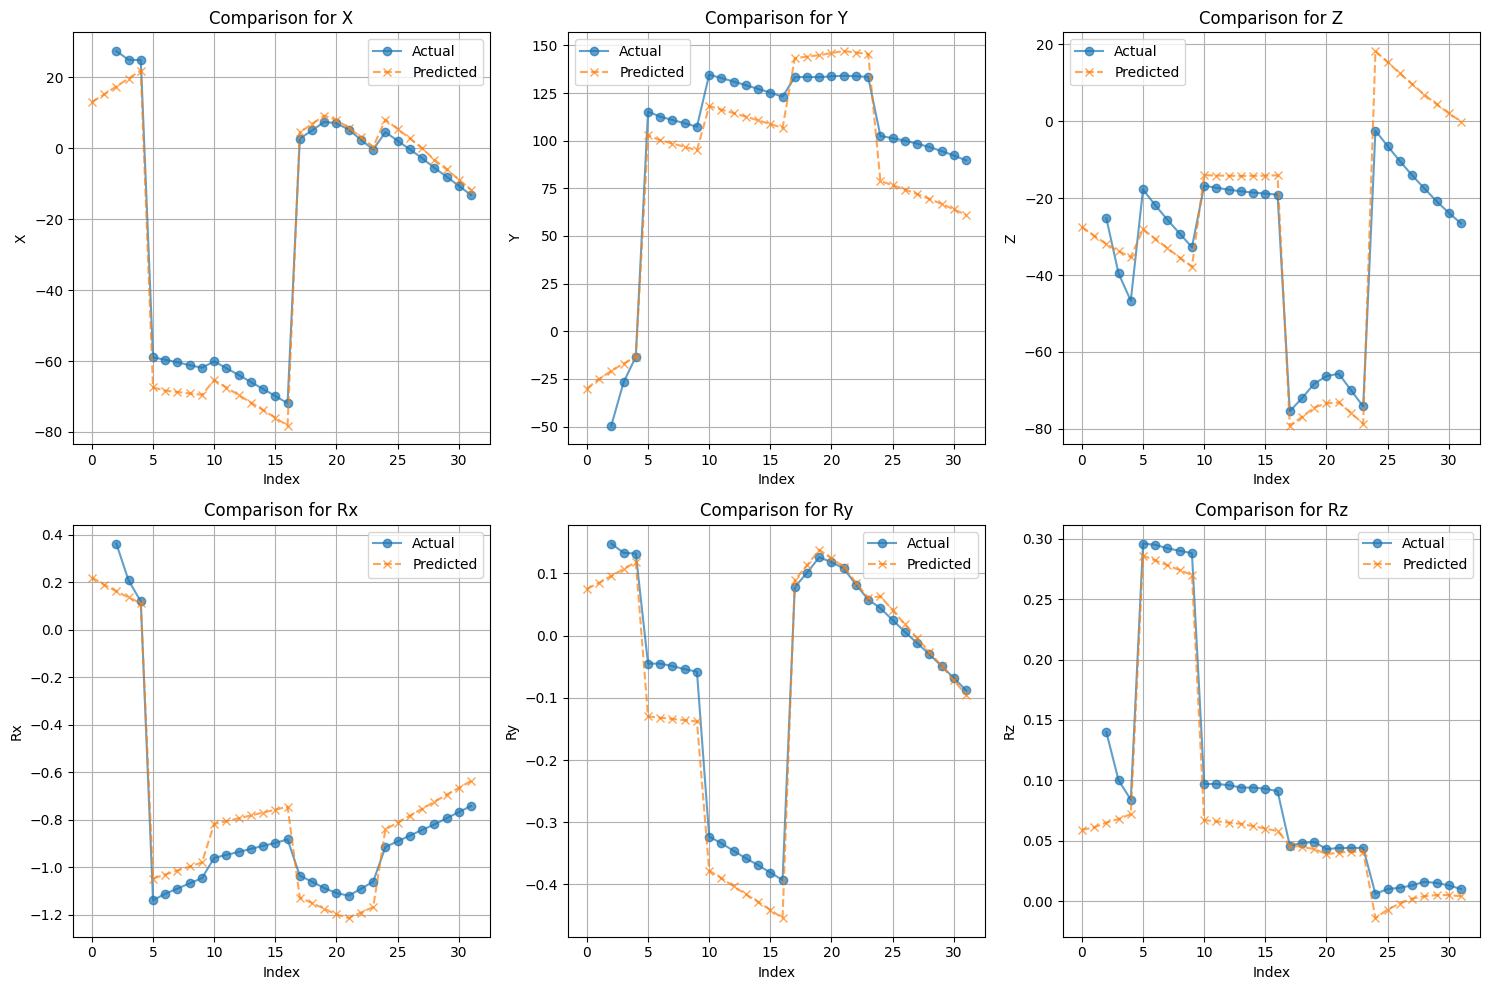

In [ ]:
plot_comparison(res, tests)

##<font color='orange'>Random Forest Regressor model evaluation - <font color='yellow'>Quite good on generated data</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 10.3282
  R2 Score: 0.9910
Target L2:
  Mean Squared Error: 12.2598
  R2 Score: 0.9855
Target L3:
  Mean Squared Error: 6.9011
  R2 Score: 0.9939
Target L4:
  Mean Squared Error: 10.2557
  R2 Score: 0.9890
Target L5:
  Mean Squared Error: 6.1314
  R2 Score: 0.9943

Feature Importances:
    Importance
X     0.197425
Y     0.188359
Z     0.279485
RX    0.086302
RY    0.046462
RZ    0.201968


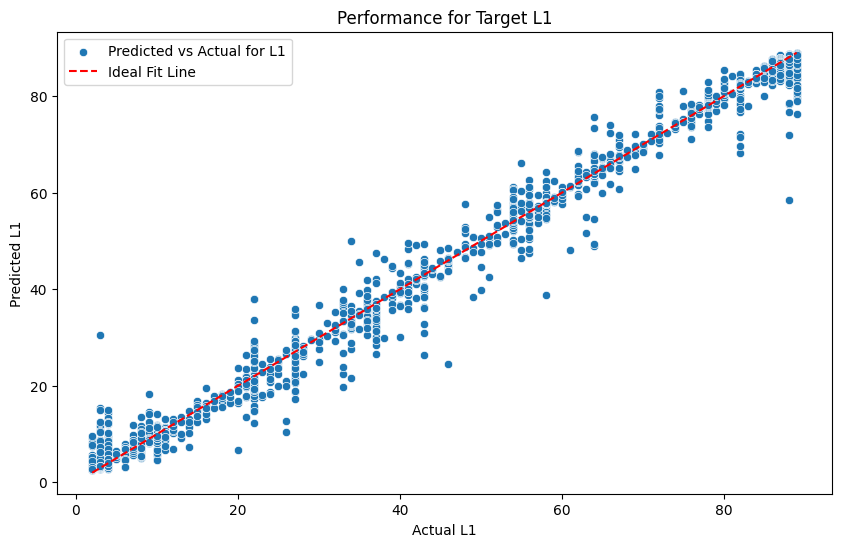

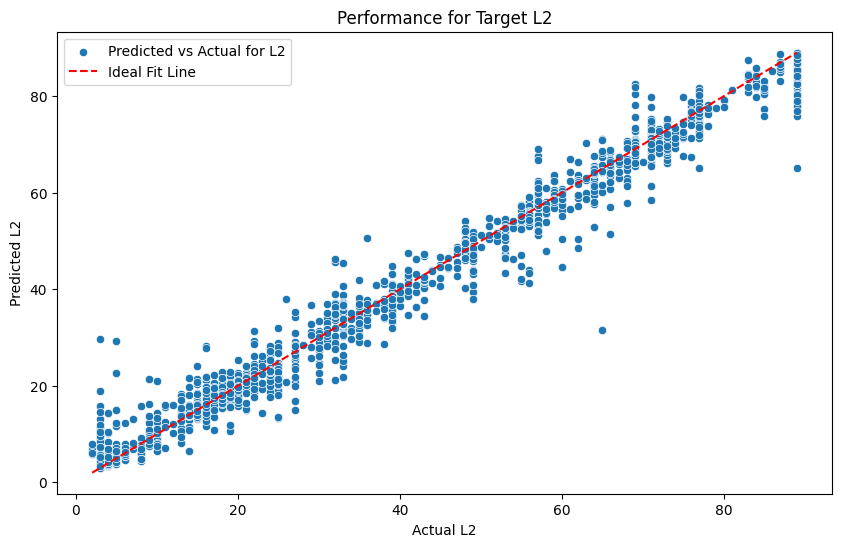

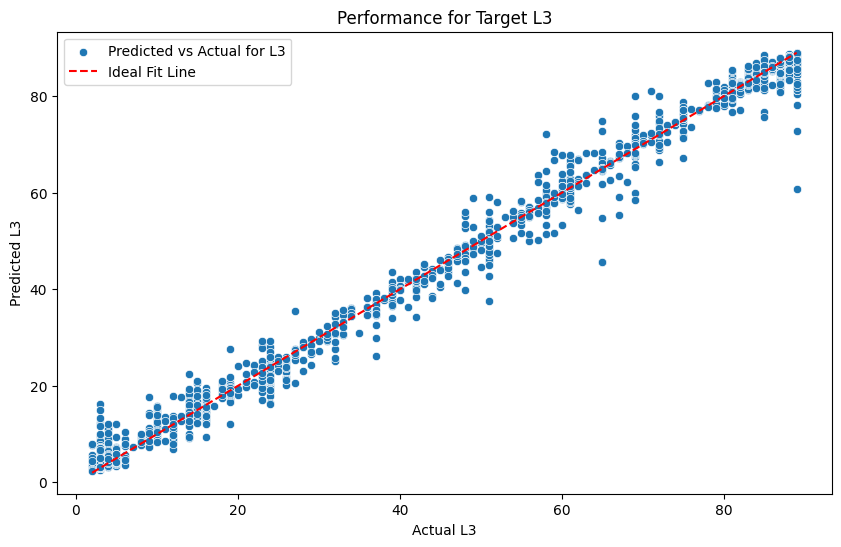

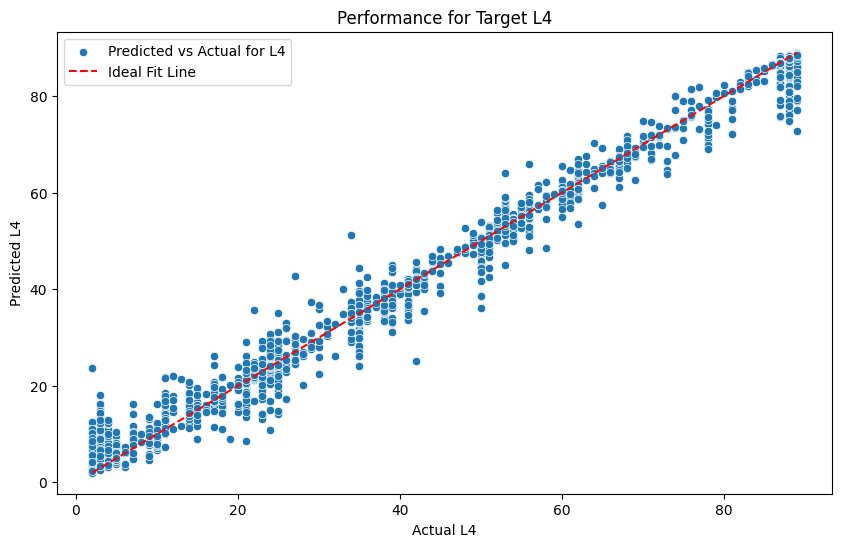

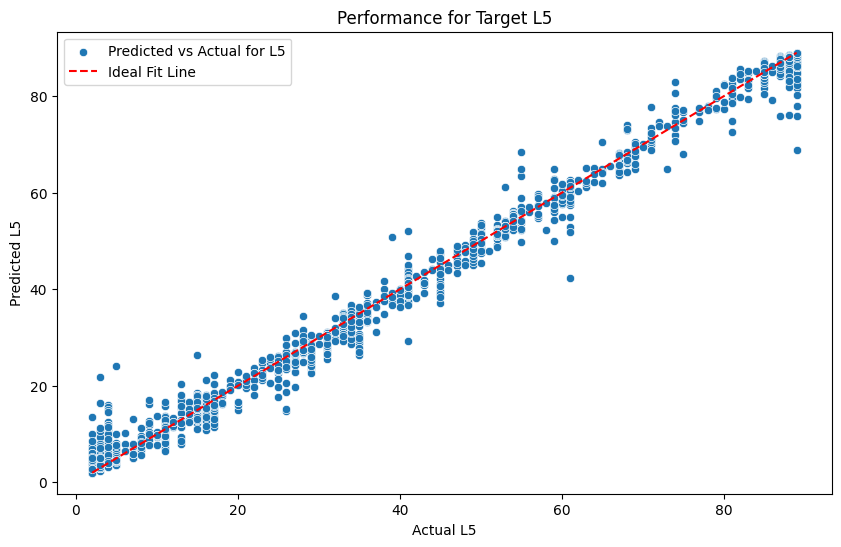

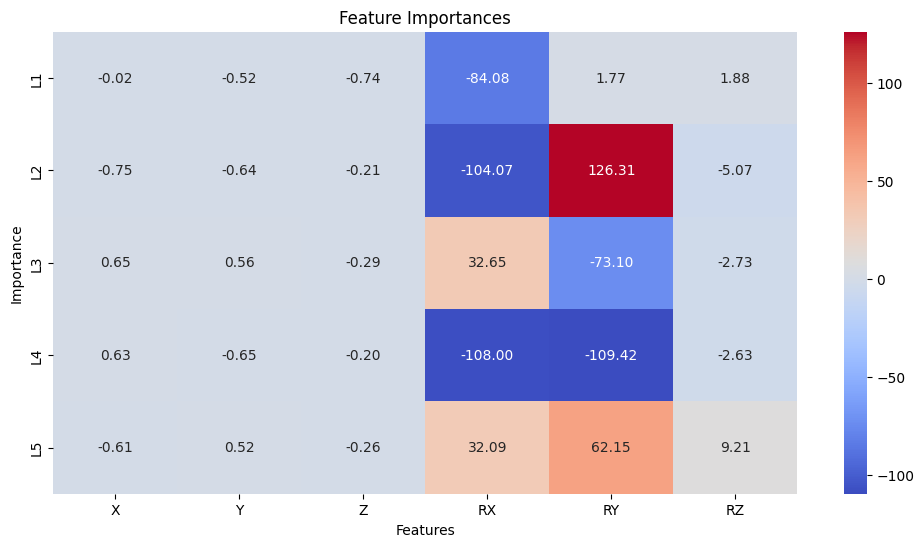

In [ ]:
from sklearn.ensemble import RandomForestRegressor



labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

feature_importances = pd.DataFrame(model.feature_importances_, index=features.columns, columns=['Importance'])

print("\nFeature Importances:")
print(feature_importances)

# Visualization
for i, target in enumerate(labels):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
            color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
#sns.barplot(x=feature_importances.index, y=feature_importances['Importance'], palette='coolwarm')
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Feature Importances")
plt.ylabel("Importance")
plt.xlabel("Features")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-6.553, 8.355, -24.27, -0.104, 0.023, 0.096]) # The simulation check for these values

[[ 3.74 36.52  5.01 22.34 21.09]]


[-5, -1, -20, -0.053, 0.036, 0.103]
[-6.553, 8.355, -24.27, -0.104, 0.023, 0.096]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


The simulation validation <font color='red'>failed</font>.

In [ ]:
#@title testing on generated data

# Predicting Ls based on generated data
with open('rfr_predictions.txt', 'w') as writefile:
    for i in tests:
        y_pred = model.predict([i]).tolist()
        writefile.write(f'{y_pred[0][0]}, {y_pred[0][1]}, {y_pred[0][2]}, {y_pred[0][3]}, {y_pred[0][4]}\n')

# Importing results check in simulation
with open("rfr_tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

print(res)


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/

[[12.275, -25.879, -31.718, 0.203, 0.068, 0.052], [15.543, -19.623, -33.81, 0.162, 0.085, 0.057], [17.733, -17.931, -34.037, 0.151, 0.094, 0.055], [21.391, -14.844, -35.058, 0.122, 0.114, 0.059], [22.514, -12.544, -36.487, 0.102, 0.121, 0.063], [-70.737, 105.053, -23.573, -1.061, -0.157, 0.292], [-70.343, 101.618, -28.453, -1.035, -0.155, 0.282], [-70.523, 98.882, -32.27, -1.019, -0.152, 0.279], [-70.187, 96.985, -34.9, -0.998, -0.147, 0.276], [-70.097, 93.855, -38.875, -0.974, -0.148, 0.269], [-66.412, 118.428, -14.007, -0.821, -0.382, 0.068], [-69.251, 117.399, -14.247, -0.81, -0.396, 0.069], [-69.774, 115.17, -14.186, -0.798, -0.4, 0.067], [-70.347, 115.063, -14.187, -0.796, -0.403, 0.068], [-73.008, 113.458, -14.427, -0.791, -0.419, 0.067], [-75.876, 107.923, -14.755, -0.756, -0.435, 0.065], [-78.859, 107.446, -14.217, -0.753, -0.455, 0.061], [3.369, 143.463, -79.898, -1.142, 0.094, 0.045], [5.609, 143.872, -78.109, -1.157, 0.114, 0.046], [7.913, 145.181, -75.21, -1.183, 0.132, 0.0

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/

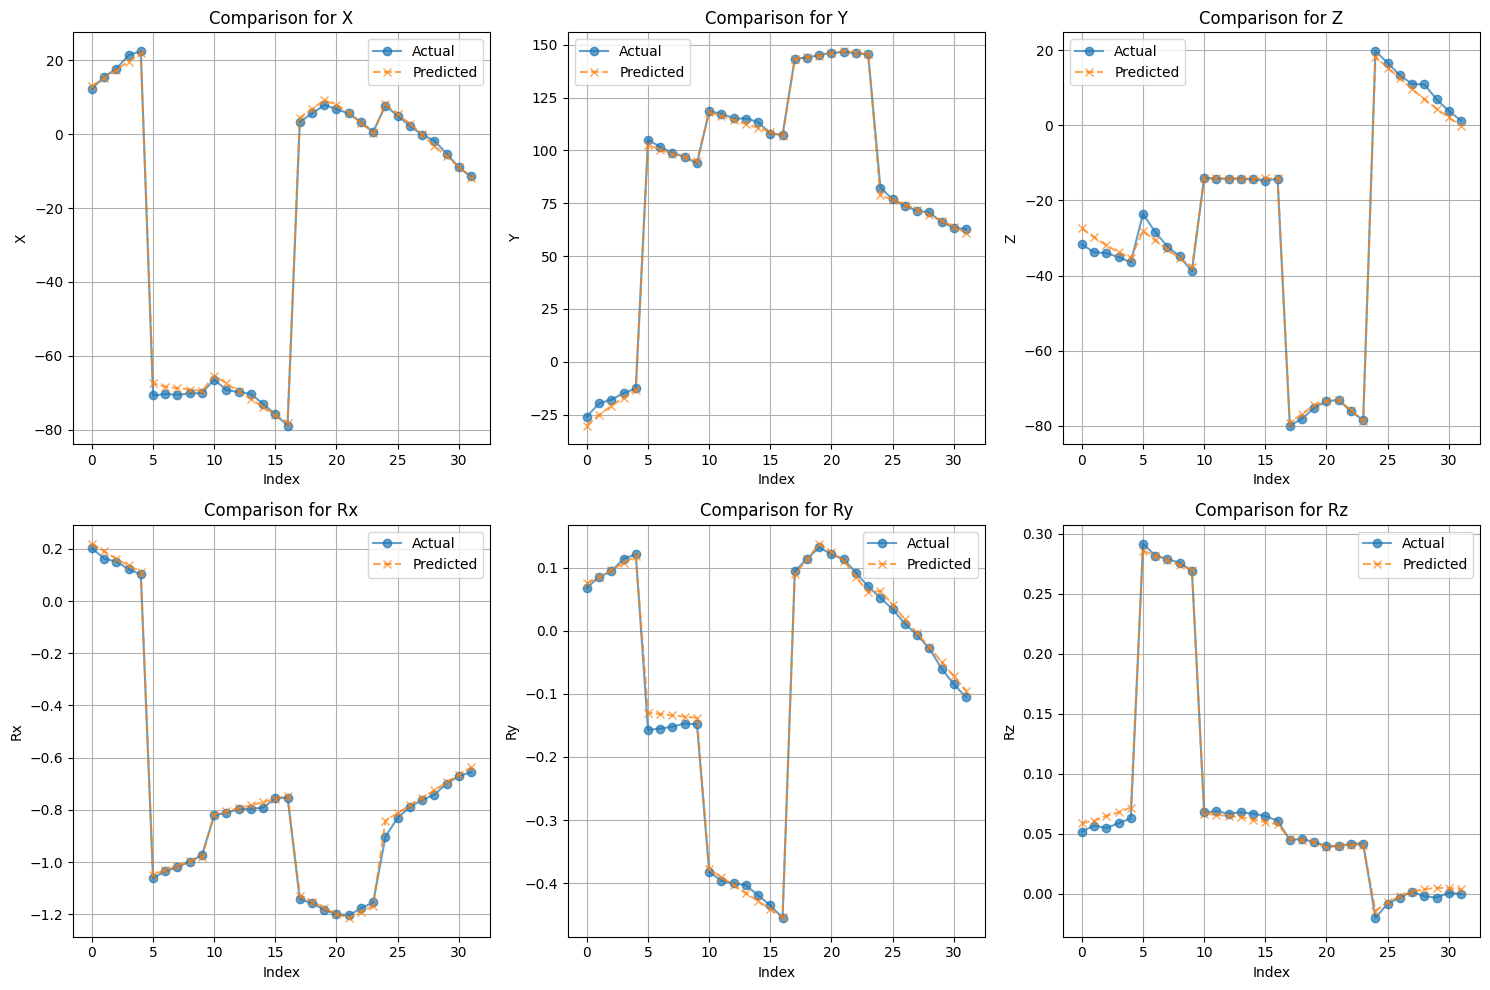

In [ ]:
plot_comparison(res, tests)

##<font color='orange'>KNeighborsRegressor model evaluation - <font color='yellow'>better than PNF on generated data</font>

Performance Metrics:
Target L1:
  Mean Squared Error: 71.8768
  R2 Score: 0.9373
Target L2:
  Mean Squared Error: 136.2350
  R2 Score: 0.8391
Target L3:
  Mean Squared Error: 40.3524
  R2 Score: 0.9646
Target L4:
  Mean Squared Error: 204.5982
  R2 Score: 0.7800
Target L5:
  Mean Squared Error: 44.6934
  R2 Score: 0.9585


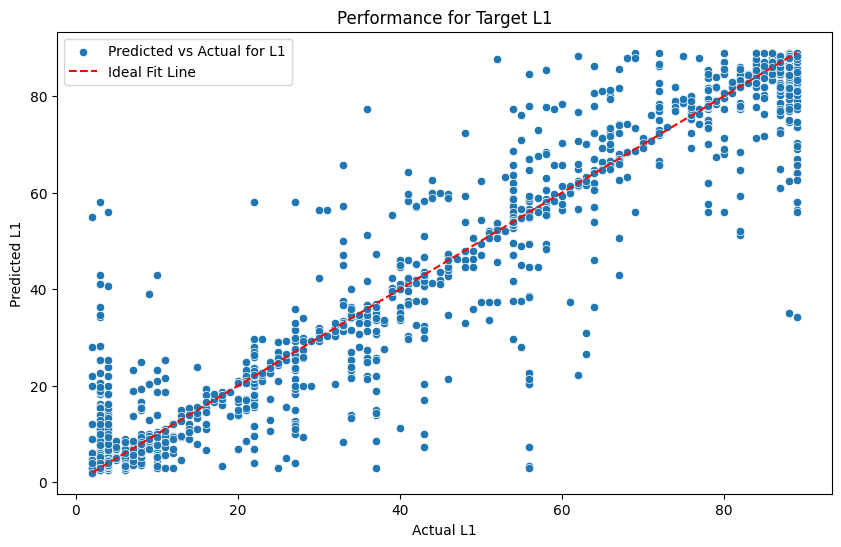

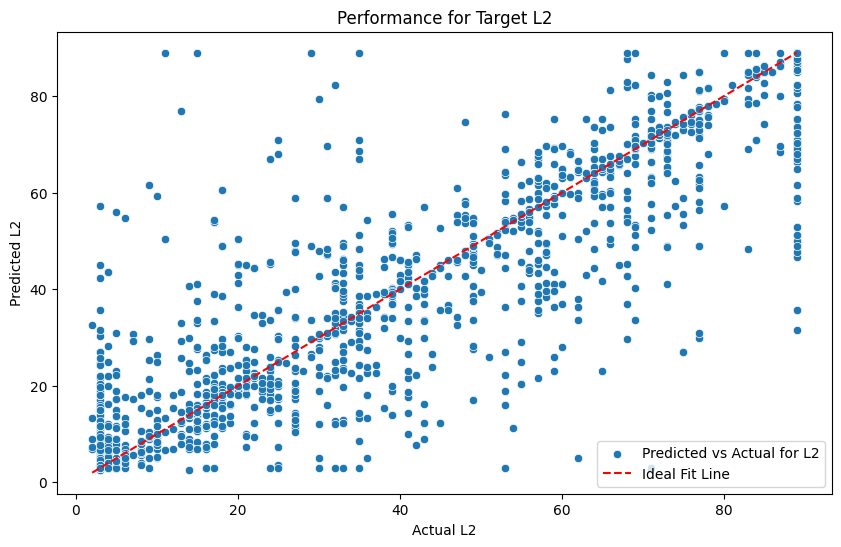

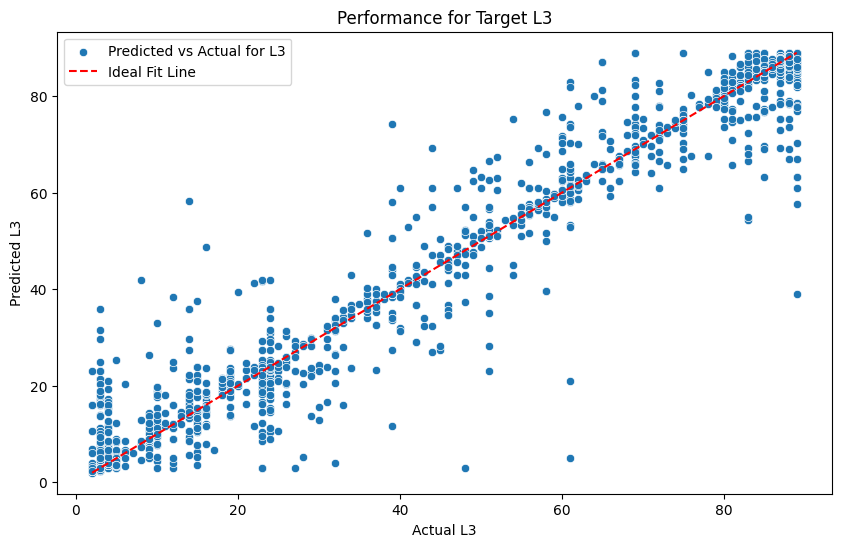

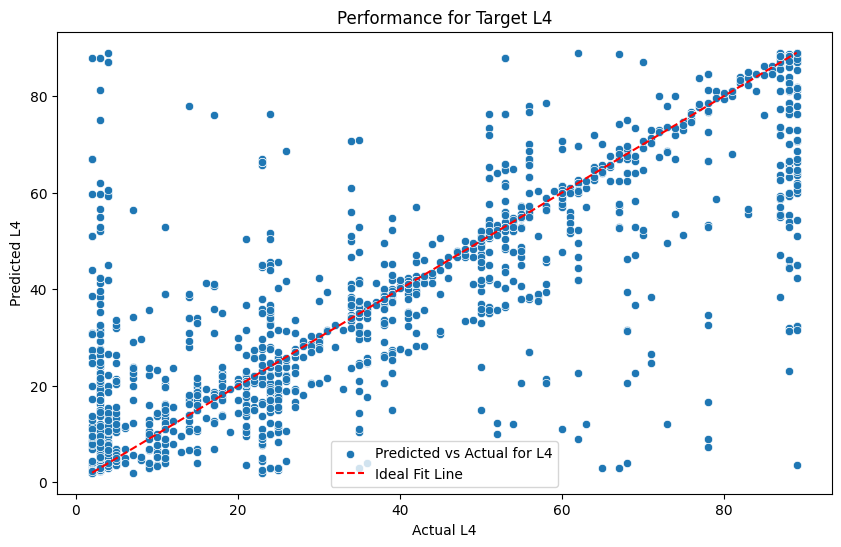

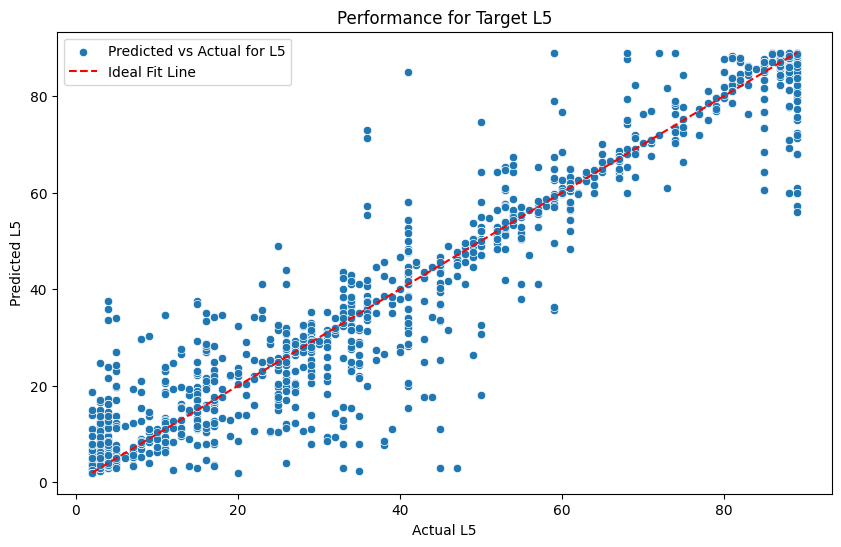

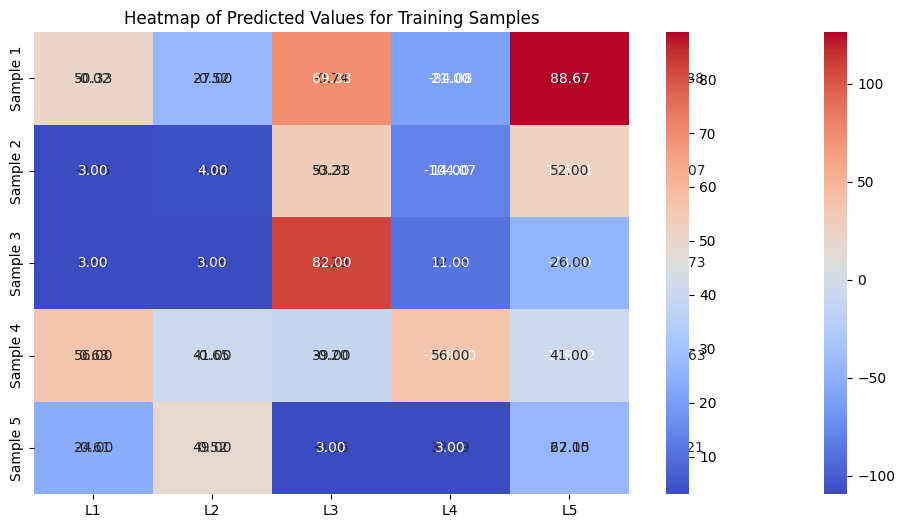

In [ ]:
from sklearn.neighbors import KNeighborsRegressor


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

n_neighbors = 3  # Number of neighbors to consider
model = KNeighborsRegressor(n_neighbors=n_neighbors)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(coefficients, annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
sns.heatmap(pd.DataFrame(model.predict(X_train)[:5], columns=labels.columns, index=[f"Sample {i+1}" for i in range(5)]), annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Predicted Values for Training Samples")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [-5, -1, -20, -0.053, 0.036, 0.103]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)

print(target)
print([-5.6, 2.845, -21.319, -0.083, 0.032, 0.101]) # The simulation check for these values

[[ 4. 39.  3. 24. 20.]]
[-5, -1, -20, -0.053, 0.036, 0.103]
[-5.6, 2.845, -21.319, -0.083, 0.032, 0.101]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(


The simulation validation <font color='orange'>close</font>, consider tuning the parameters.

In [ ]:
#@title testing on generated data

# Predicting Ls based on generated data
with open('knr_predictions.txt', 'w') as writefile:
    for i in tests:
        y_pred = model.predict([i]).tolist()
        writefile.write(f'{y_pred[0][0]}, {y_pred[0][1]}, {y_pred[0][2]}, {y_pred[0][3]}, {y_pred[0][4]}\n')

# Importing results check in simulation
with open("knr_tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

print(res)


[[9.79, -31.811, -30.003, 0.271, 0.056, 0.057], [16.894, -23.94, -29.669, 0.205, 0.078, 0.026], [16.509, -21.506, -32.928, 0.169, 0.093, 0.066], [16.09, -12.267, -34.855, 0.131, 0.074, 0.02], [20.395, -13.287, -36.103, 0.117, 0.114, 0.073], [-67.805, 101.823, -26.098, -1.058, -0.132, 0.286], [-67.805, 101.823, -26.098, -1.058, -0.132, 0.286], [-68.443, 97.873, -32.336, -1.018, -0.137, 0.277], [-70.994, 98.456, -36.97, -0.9, -0.185, 0.252], [-69.064, 93.798, -38.326, -0.979, -0.142, 0.268], [-64.763, 119.478, -13.81, -0.825, -0.372, 0.068], [-68.827, 115.761, -14.065, -0.801, -0.396, 0.066], [-68.827, 115.761, -14.065, -0.801, -0.396, 0.066], [-71.558, 114.648, -13.341, -0.791, -0.375, 0.109], [-75.679, 111.007, -13.417, -0.75, -0.329, 0.185], [-76.706, 110.127, -13.754, -0.751, -0.372, 0.141], [-78.338, 107.833, -14.205, -0.742, -0.42, 0.095], [1.154, 149.552, -77.195, -1.027, 0.055, 0.043], [3.947, 150.885, -75.281, -1.045, 0.077, 0.045], [8.299, 145.838, -73.666, -1.194, 0.134, 0.041

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11

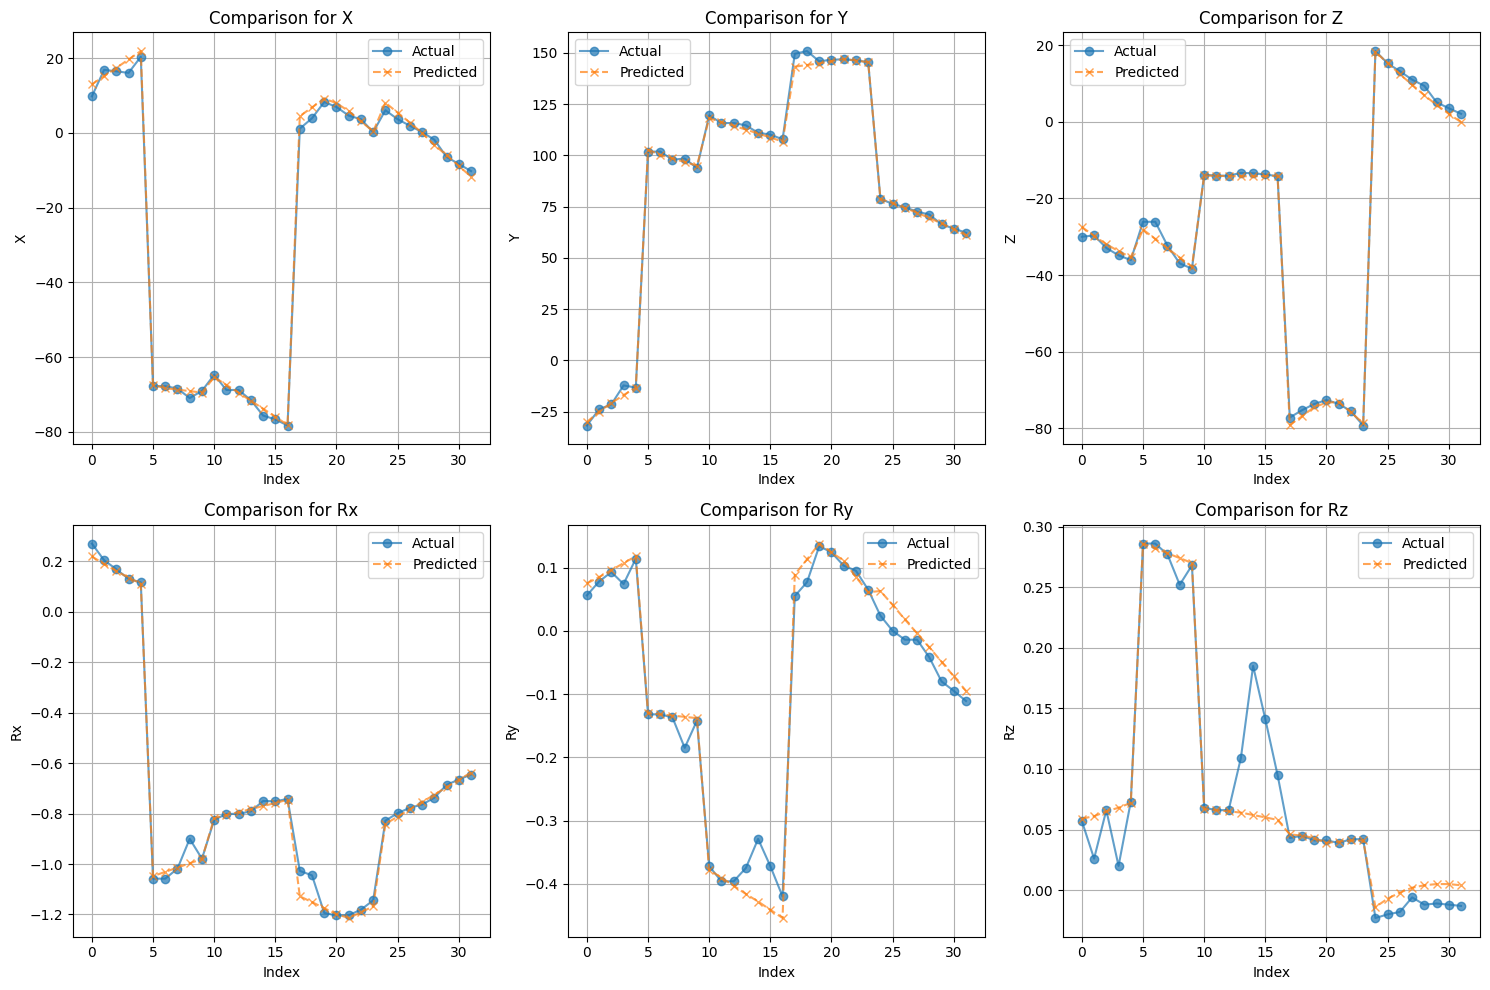

In [ ]:
plot_comparison(res, tests)

##<font color='orange'>PolynomialFeatures model evaluation - <font color='yellow'>errors occur but its simulation defect rather than model's one</font>

Polynomial regression transforms data into a higher-dimensional space with polynomial features.
Linear Regression then fits a line (hyperplane) in this transformed space.

Performance Metrics:
Target L1:
  Mean Squared Error: 0.1204
  R2 Score: 0.9999
Target L2:
  Mean Squared Error: 0.5743
  R2 Score: 0.9993
Target L3:
  Mean Squared Error: 0.2555
  R2 Score: 0.9998
Target L4:
  Mean Squared Error: 0.6309
  R2 Score: 0.9993
Target L5:
  Mean Squared Error: 0.2837
  R2 Score: 0.9997


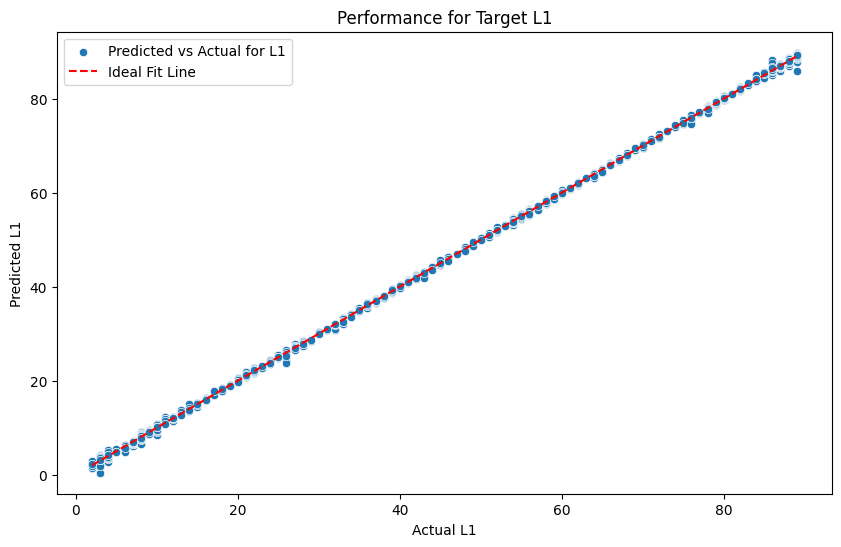

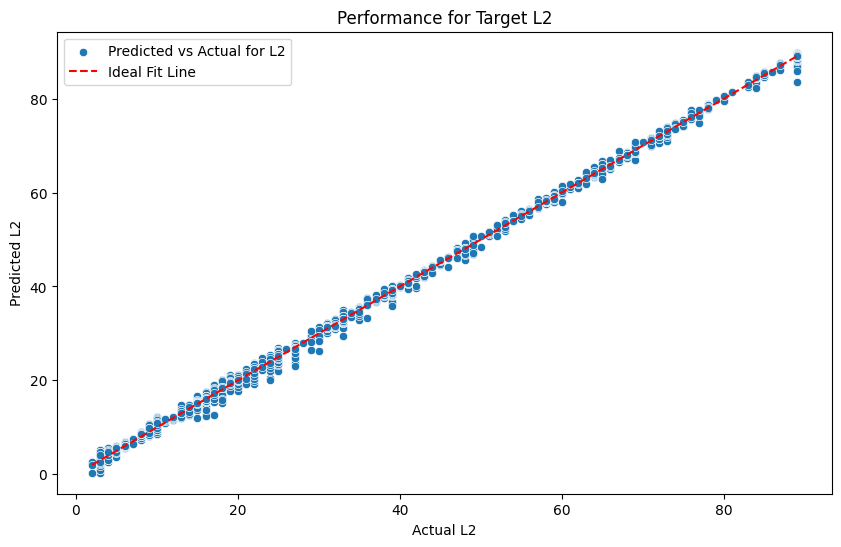

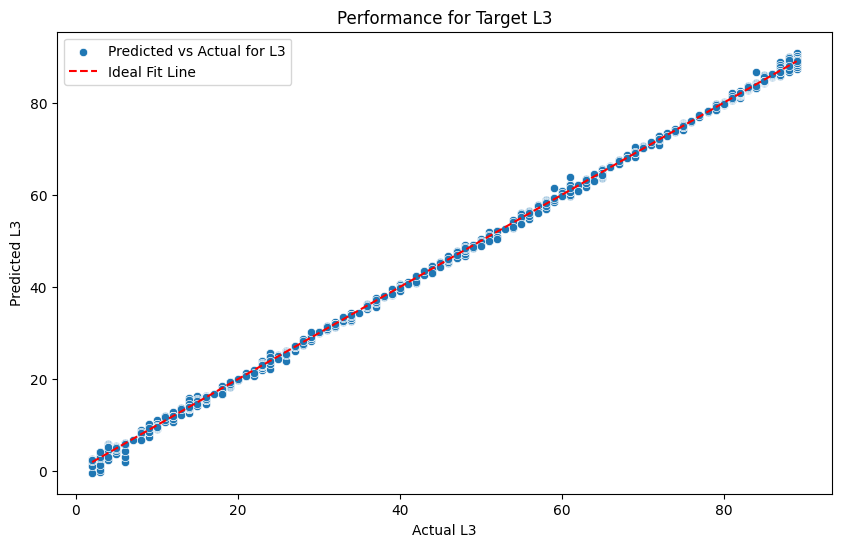

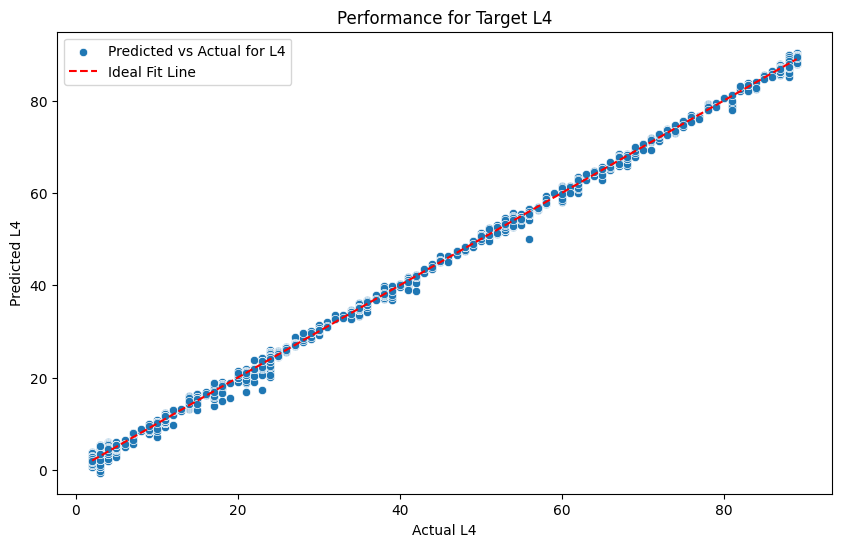

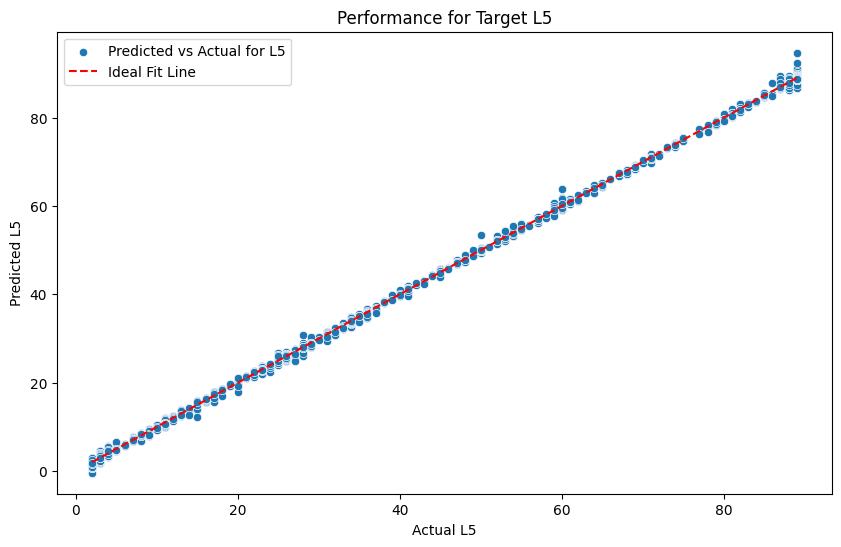

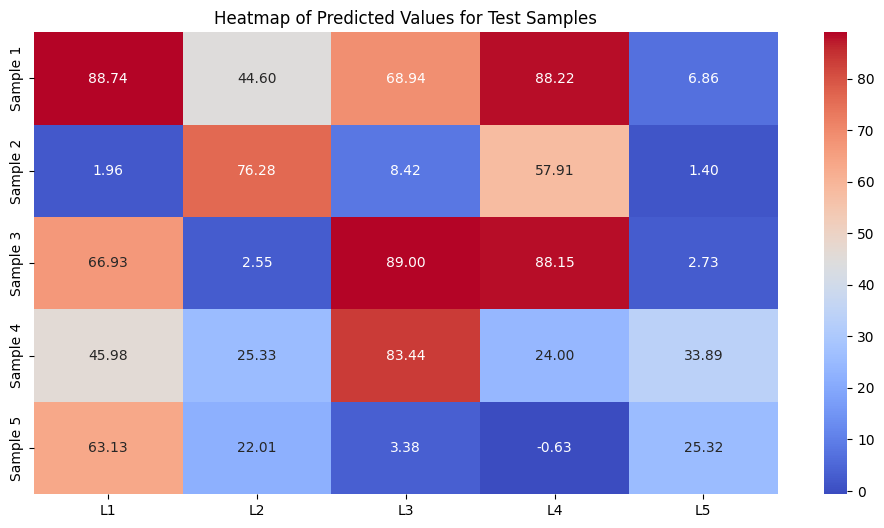

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline


labels = data[['L1', 'L2', 'L3', 'L4', 'L5']]
features = data[['X', 'Y', 'Z', 'RX', 'RY', 'RZ']]

X_train, X_test, y_train, y_test = train_test_split(features, labels, test_size=0.2, random_state=42)

degree = 3

model = make_pipeline(PolynomialFeatures(degree), LinearRegression())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

# Evaluate the model
mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
r2 = r2_score(y_test, y_pred, multioutput='raw_values')

print("Performance Metrics:")
for i, target in enumerate(labels.columns):
    print(f"Target {target}:")
    print(f"  Mean Squared Error: {mse[i]:.4f}")
    print(f"  R2 Score: {r2[i]:.4f}")

# Visualization
for i, target in enumerate(labels.columns):
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x=y_test.iloc[:, i], y=y_pred[:, i], label=f'Predicted vs Actual for {target}')
    plt.plot([y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             [y_test.iloc[:, i].min(), y_test.iloc[:, i].max()],
             color='red', linestyle='--', label='Ideal Fit Line')
    plt.xlabel(f"Actual {target}")
    plt.ylabel(f"Predicted {target}")
    plt.title(f"Performance for Target {target}")
    plt.legend()
    plt.show()

plt.figure(figsize=(12, 6))
sns.heatmap(pd.DataFrame(y_pred[:5], columns=labels.columns, index=[f"Sample {i+1}" for i in range(5)]),
            annot=True, fmt=".2f", cmap='coolwarm', cbar=True)
plt.title("Heatmap of Predicted Values for Test Samples")
plt.show()


In [ ]:
# Trying to get LAs for X=0, Y=0, Z=0, RX=0, RY=0, RZ=0
# ['3.0', '39.0', '3.0', '24.0', '20.0', '-4.888', '-1.352', '-19.097', '-0.053', '0.036', '0.103'] - one of the entries. an example was predicted for values close to it.

target = [0, 0, 10, 0, 0, 0]
y_pred = model.predict([target])
np.set_printoptions(precision=4, suppress=True)
print(y_pred)
print("\n")
print(target)
print([-5.331, -2.635, -19.697, -0.043, 0.033, 0.104]) # The simulation check for these values

[[-20.174   29.8392  13.8501  33.4323  16.8361]]


[0, 0, 10, 0, 0, 0]
[-5.331, -2.635, -19.697, -0.043, 0.033, 0.104]


/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


The simulation validation <font color='orange'>quite close</font>, possibly, data re-engineering is necessary...

In [ ]:
#@title testing on generated data

# Predicting Ls based on generated data
with open('pnf_predictions.txt', 'w') as writefile:
    for i in tests:
        y_pred = model.predict([i]).tolist()
        writefile.write(f'{y_pred[0][0]}, {y_pred[0][1]}, {y_pred[0][2]}, {y_pred[0][3]}, {y_pred[0][4]}\n')

# Importing results check in simulation
with open("pnf_tested.txt", 'r') as file:
    res = [[float(i) for i in x.strip().split(',')] for x in file.readlines()]

print(res)


[[11.115, -22.202, -32.061, 0.165, 0.068, 0.059], [13.629, -19.148, -33.213, 0.148, 0.081, 0.062], [16.155, -16.382, -34.505, 0.131, 0.094, 0.067], [18.671, -13.563, -35.699, 0.113, 0.107, 0.071], [21.157, -10.877, -36.745, 0.096, 0.121, 0.076], [-65.434, 100.678, -28.789, -1.045, -0.121, 0.276], [-67.759, 99.037, -30.854, -1.027, -0.126, 0.282], [-68.567, 97.584, -33.222, -1.009, -0.129, 0.28], [-69.431, 96.172, -35.507, -0.992, -0.133, 0.279], [-70.296, 94.743, -37.733, -0.975, -0.136, 0.278], [-64.866, 117.878, -14.154, -0.818, -0.377, 0.064], [-67.13, 116.087, -14.219, -0.806, -0.389, 0.064], [-69.016, 114.273, -14.29, -0.795, -0.401, 0.062], [-70.929, 112.413, -14.349, -0.784, -0.414, 0.059], [-73.487, 110.504, -14.28, -0.771, -0.427, 0.06], [-75.74, 108.546, -14.23, -0.758, -0.441, 0.058], [-77.897, 106.616, -14.107, -0.746, -0.453, 0.056], [5.757, 141.557, -79.987, -1.125, 0.093, 0.036], [7.835, 143.034, -77.305, -1.15, 0.115, 0.037], [10.046, 144.432, -74.487, -1.176, 0.139, 0.

/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.11/dist

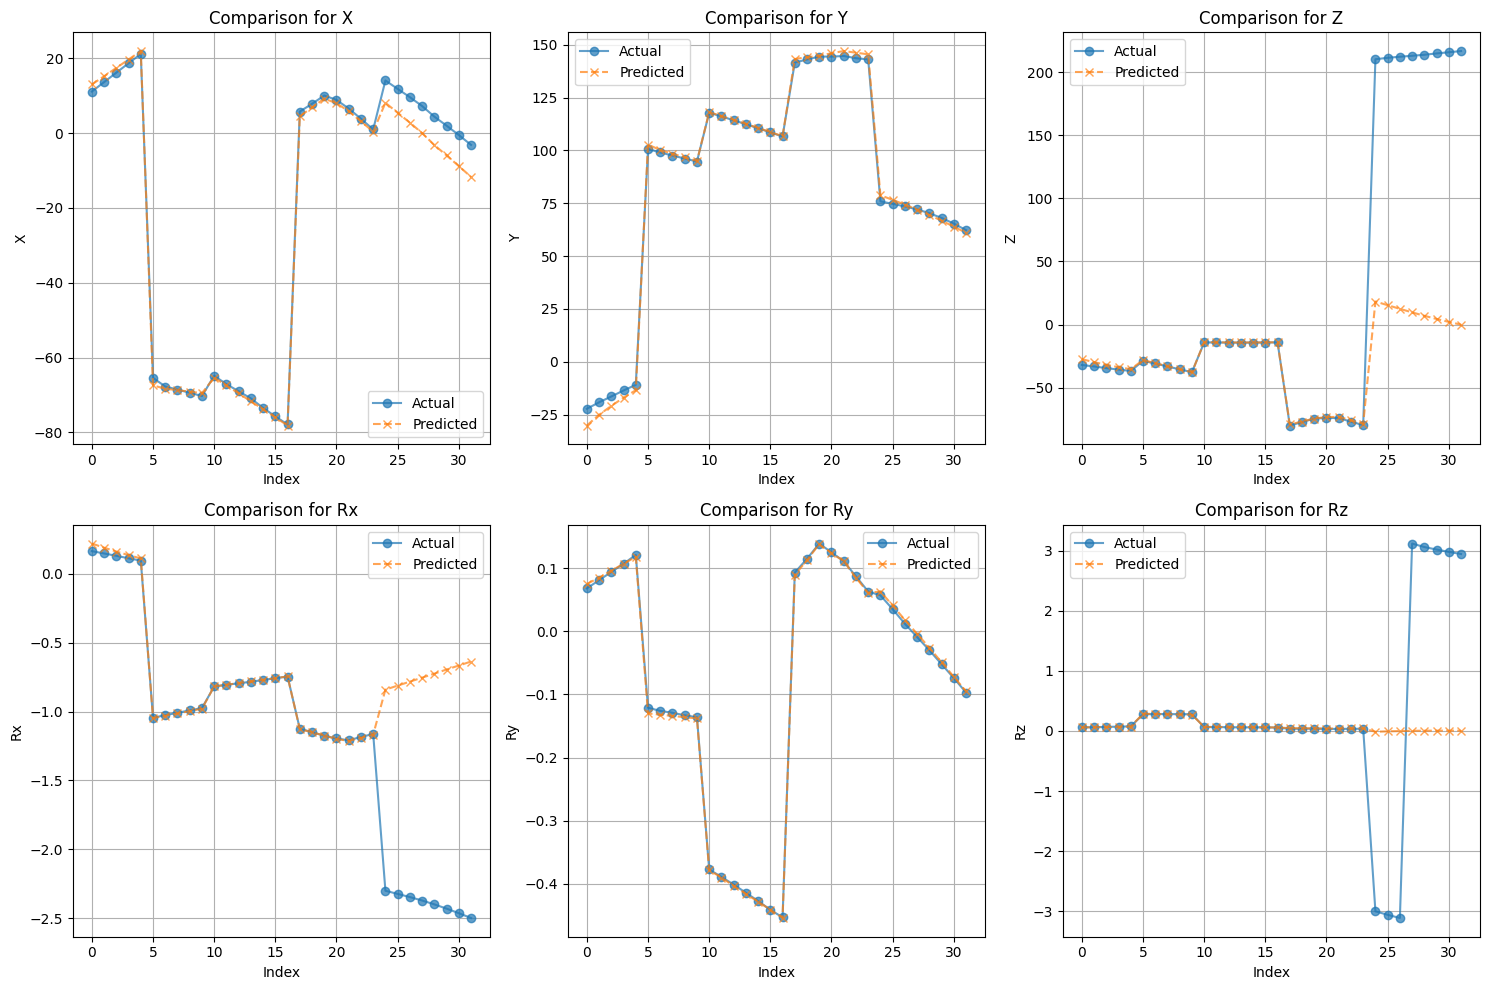

In [ ]:
plot_comparison(res, tests)

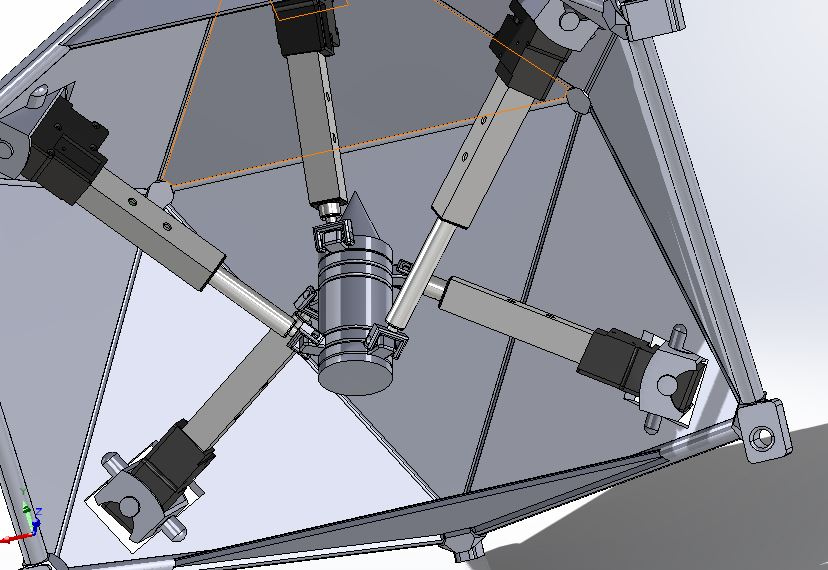

In [ ]:
from IPython.display import Image
Image(filename='pnf_error.JPG')

##<font color='red'>CONCLUSION:</font>

A more diverse testings were made on data, generated by ChatGPT using the dataset acquired from simulation. All in all, there are some models which may be considered for further development:
  * Random Forest Regressor
  * KNeighbours Regressor
  * Polynomial Features

The last model testings were giving unrealistic configuration changes, more likely because of the sudden big jump in values, thats why the simulated on predictions data (checked one) diverse much from the predicted values (you can see that on the plots, after index ~23) and performs worse than other models.